<a href="https://colab.research.google.com/github/Hunchovelli/2025-01-diva/blob/main/Car_Insurance_Claims_Predictions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import PCA

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

from scipy.stats import zscore

#load the dataset
df = pd.read_csv('car_insurance_claim.csv')


Data Cleaning

In [ ]:
#drops duplicate values
df.drop_duplicates(inplace = True)

In [ ]:
df.drop(['ID', 'BIRTH'], axis = 1, inplace = True)

In [ ]:
df.isnull().sum()

,0
KIDSDRIV,0
AGE,7
HOMEKIDS,0
YOJ,548
INCOME,570
PARENT1,0
HOME_VAL,575
MSTATUS,0
GENDER,0
EDUCATION,0


In [ ]:
#columns with $ symbols
currency_cols = ["INCOME", "HOME_VAL", "BLUEBOOK", "OLDCLAIM", "CLM_AMT"]

#removes the '$' and ',' value from all the columns that have a $ symbol in them
def format_currency_cols(df, cols):
  for col in cols:
    #remove currency symbols and commas
    df[col] = df[col].astype(str).str.replace('[\$,]', '', regex=True).replace('',np.nan)
    #convert to nullable interger type
    df[col] = pd.to_numeric(df[col], errors='coerce').astype('Int64')
  return df

df = format_currency_cols(df, currency_cols)

In [ ]:
#columns with z_ prefix
z_prefix_cols = ["MSTATUS", "GENDER", "EDUCATION", "OCCUPATION", "CAR_TYPE", "URBANICITY"]

#removes the 'z' value from all the columns that have a $ symbol in them
def remove_prefix(df, cols):
  for col in cols:
    df[col] = df[col].replace('[z_]', '', regex=True)
  return df

df = remove_prefix(df, z_prefix_cols)

Exploratory Data Analysis


In [ ]:
#store the numerical and categorical columns in their respective variables
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
cat_cols = df.select_dtypes(include=["object"]).columns

#setting the mode for the numerical imputer
num_imputer = SimpleImputer(strategy="median")
#setting the mode for the categorical imputer
cat_imputer = SimpleImputer(strategy="most_frequent")

#imputing the missing values: median for numerical, mode for categorical
df[num_cols] = num_imputer.fit_transform(df[num_cols])
df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])

In [ ]:
#Binary Encoding for ranked categories
binary_cols = ["PARENT1", "MSTATUS", "GENDER", "RED_CAR", "CAR_USE", "REVOKED", "URBANICITY"]

# Defining map values
mapping = {'Yes': 1,
           'No': 0,
           'yes': 1,
           'no': 0,
           'M': 1,
           'F':0,
           'Highly Urban/ Urban': 1,
           'Highly Rural/ Rural': 0,
           'Commercial': 1,
           'Private': 0
           }

def binary_encode(df, cols, map):
  for col in cols:
    df[col] = df[col].map(map)
  return df

df = binary_encode(df, binary_cols, mapping)

In [ ]:
df.head()

,KIDSDRIV,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,EDUCATION,...,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CLM_AMT,CAR_AGE,CLAIM_FLAG,URBANICITY
0,0.0,60.0,0.0,11.0,67349.0,0,0.0,0,1,PhD,...,Minivan,1,4461.0,2.0,0,3.0,0.0,18.0,0.0,1
1,0.0,43.0,0.0,11.0,91449.0,0,257252.0,0,1,High School,...,Minivan,1,0.0,0.0,0,0.0,0.0,1.0,0.0,1
2,0.0,48.0,0.0,11.0,52881.0,0,0.0,0,1,Bachelors,...,Van,1,0.0,0.0,0,2.0,0.0,10.0,0.0,1
3,0.0,35.0,1.0,10.0,16039.0,0,124191.0,1,0,High School,...,SUV,0,38690.0,2.0,0,3.0,0.0,10.0,0.0,1
4,0.0,51.0,0.0,14.0,53526.0,0,306251.0,1,1,<High School,...,Minivan,1,0.0,0.0,0,0.0,0.0,6.0,0.0,1


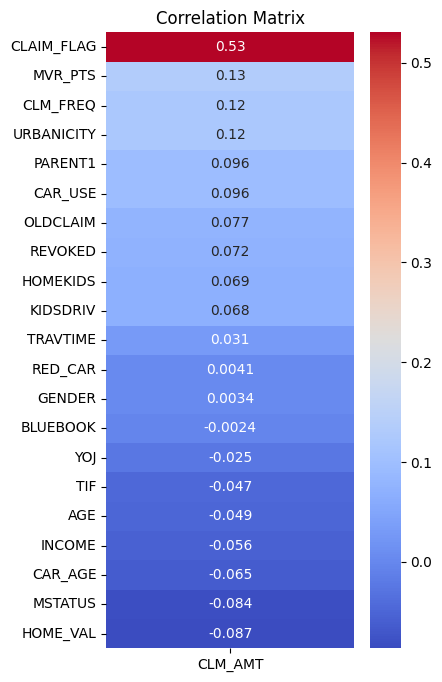

In [ ]:
#to show the correlation matrix
corr_matrix = df.corr(numeric_only=True).sort_values(by="CLM_AMT", ascending=False)
corr_matrix = corr_matrix.drop("CLM_AMT")

fig, ax = plt.subplots(figsize=(4, 8))
sns.heatmap(corr_matrix[['CLM_AMT']], annot=True, cmap="coolwarm")

plt.title("Correlation Matrix")
plt.show()

In [ ]:
#columns that are close to zero in the correlation matrix
cols_to_drop = ['RED_CAR', 'GENDER', 'BLUEBOOK']
df.drop(columns=cols_to_drop, axis = 1, inplace=True)

In [ ]:
# Define ordinal features
cat_cols_ord = ['EDUCATION']
# Define one-hot features
cat_cols_one_hot = ['OCCUPATION', 'CAR_TYPE']

In [ ]:
ranking = [['<High School','High School', 'Bachelors', 'Masters', 'PhD']]
#Define Encode Ordinals
ord_encoder = OrdinalEncoder(categories=ranking)
df["EDUCATION"] = ord_encoder.fit_transform(df[cat_cols_ord])
#One-hot encoding
one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
one_hot_encoded = one_hot_encoder.fit_transform(df[cat_cols_one_hot])

one_hot_encoded_df = pd.DataFrame(one_hot_encoded, columns=one_hot_encoder.get_feature_names_out(cat_cols_one_hot), index=df.index)
df = pd.concat([df, one_hot_encoded_df], axis=1)
df.drop(cat_cols_one_hot, axis=1, inplace=True)

In [ ]:
#MinMaxScaling
scaler = MinMaxScaler()
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
df[num_cols] = scaler.fit_transform(df[num_cols])

#ZScoreStandardisation applied to all numerical values
existing_zscore_cols = [col for col in ["AGE", "INCOME", "HOME_VAL", "YOJ", "CAR_AGE"] if col in df.columns]
df[existing_zscore_cols] = df[existing_zscore_cols].apply(zscore)


#Log Transformation applied to the original list of columns
existing_skewed_cols = [col for col in ["CLM_AMT", "KIDSDRIV", "HOMEKIDS", "TRAVTIME", "TIF", "CLM_FREQ", "MVR_PTS"] if col in df.columns]
df[existing_skewed_cols] = df[existing_skewed_cols].apply(lambda x: np.log1p(x))

In [ ]:
pca = PCA(n_components=0.95)
df2 = df.copy()
X_pca = pca.fit_transform(df2)

print("Original number of features:", df.shape[1])
print("Reduced number of features after PCA:", X_pca.shape[1])
print("Explained variance ratio per component:", pca.explained_variance_ratio_)

Original number of features: 34
Reduced number of features after PCA: 19
Explained variance ratio per component: [0.27192651 0.12722805 0.11430269 0.09351925 0.06431476 0.0469159
 0.03446385 0.02836348 0.02451695 0.02103714 0.01756088 0.01742948
 0.01668741 0.0156069  0.01328973 0.01306322 0.01184857 0.01117461
 0.00959441]


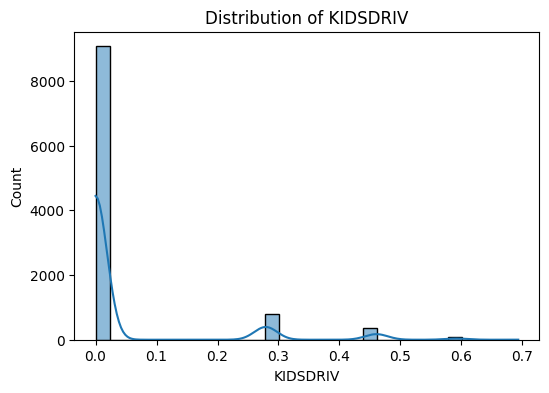

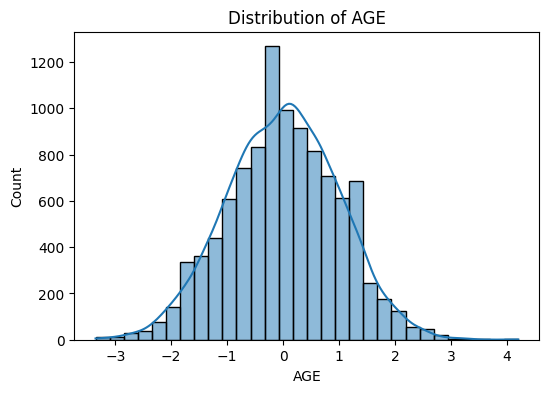

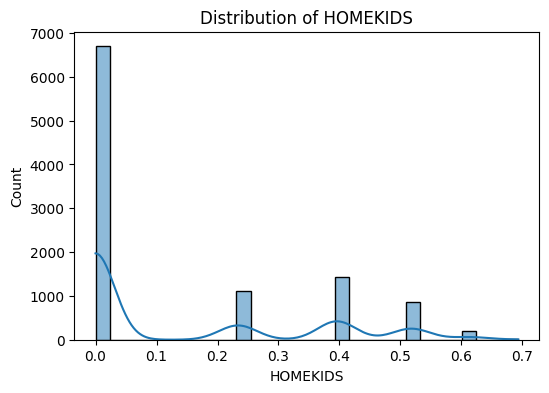

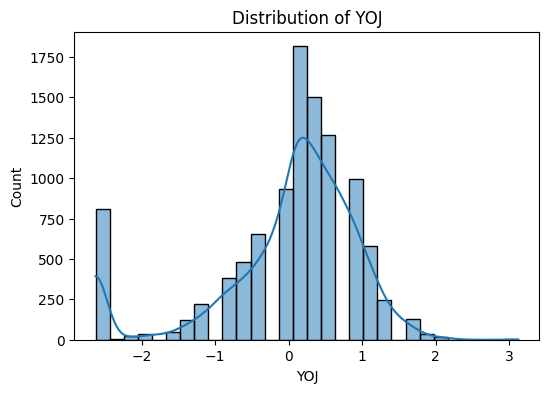

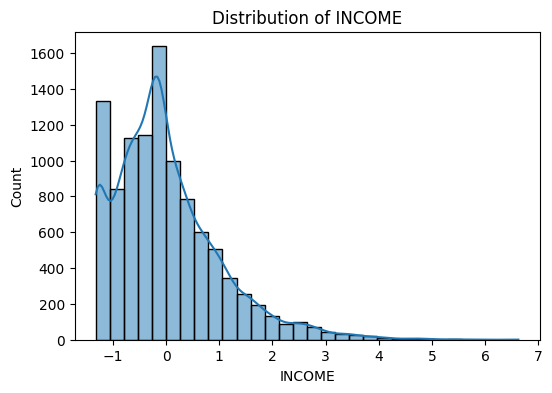

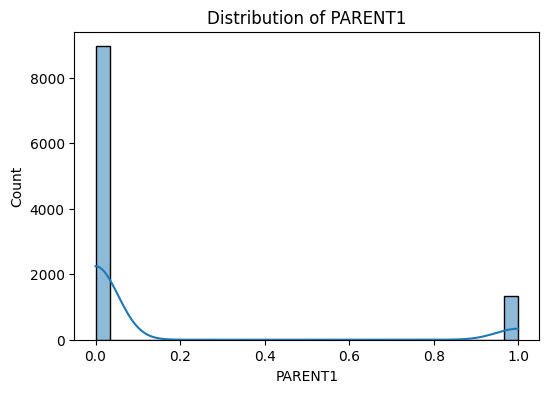

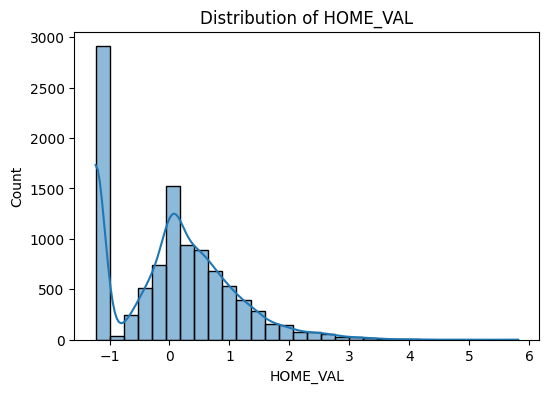

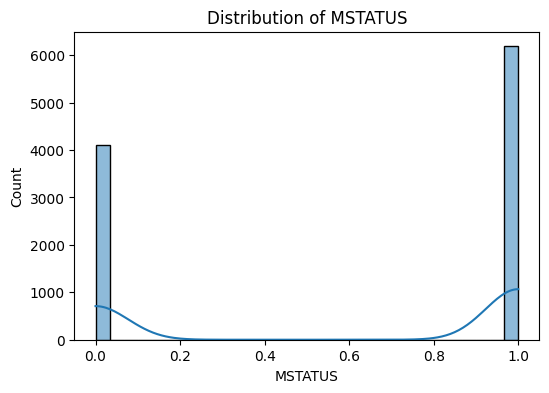

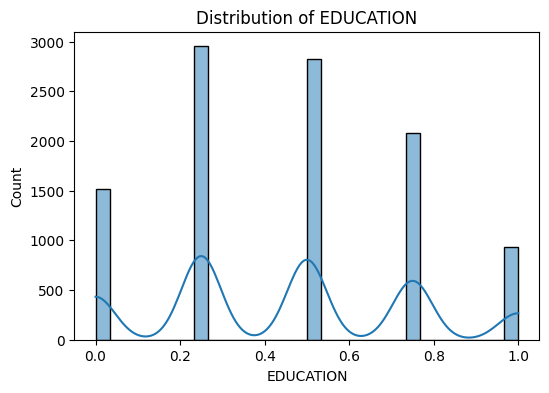

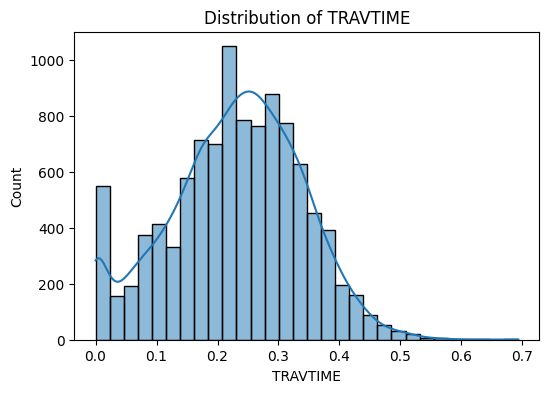

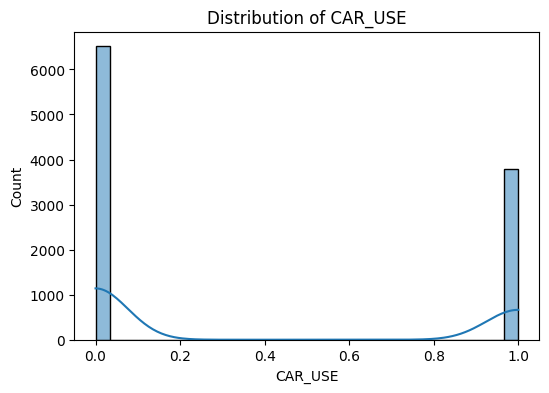

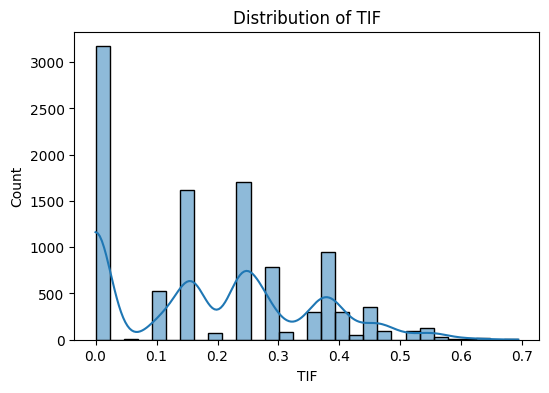

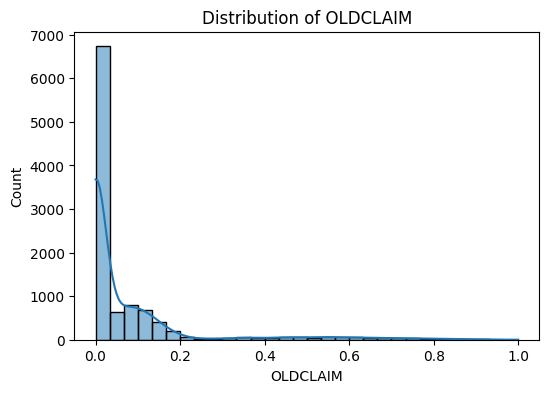

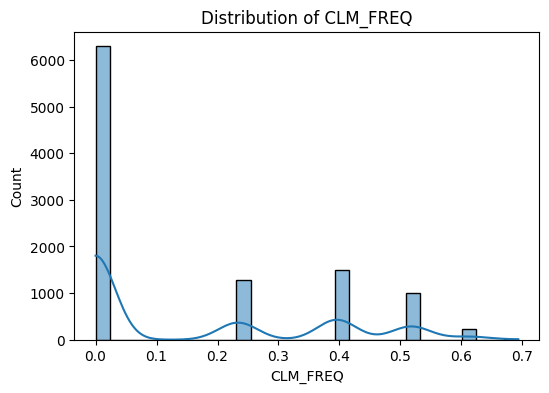

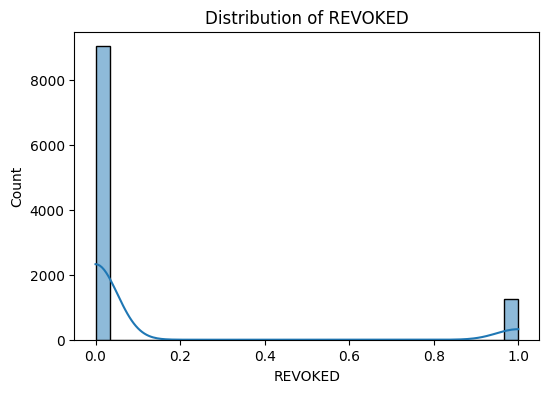

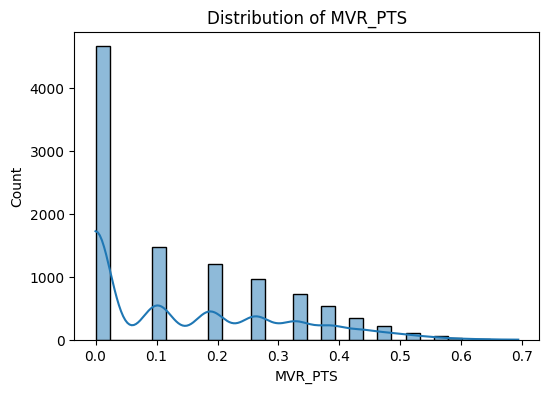

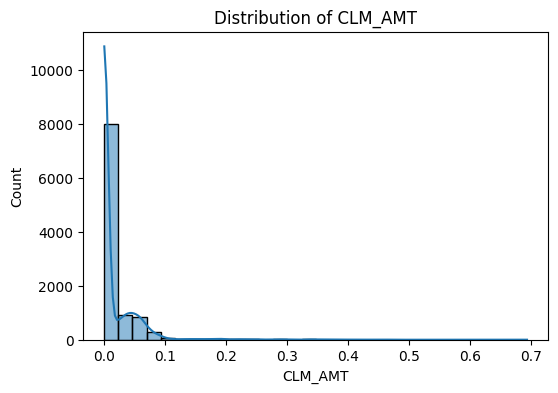

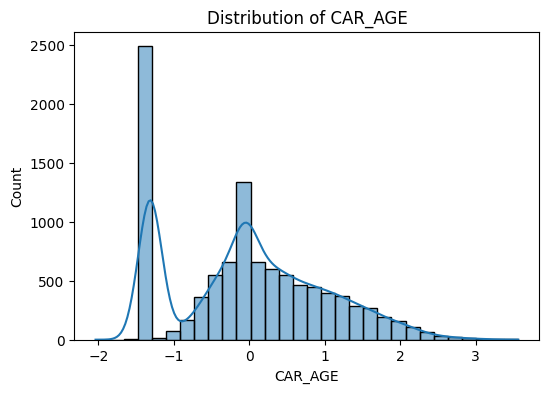

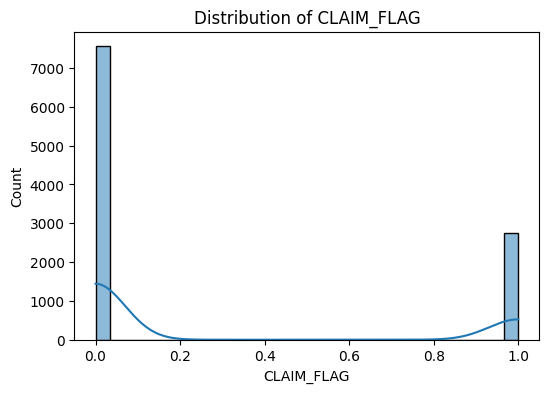

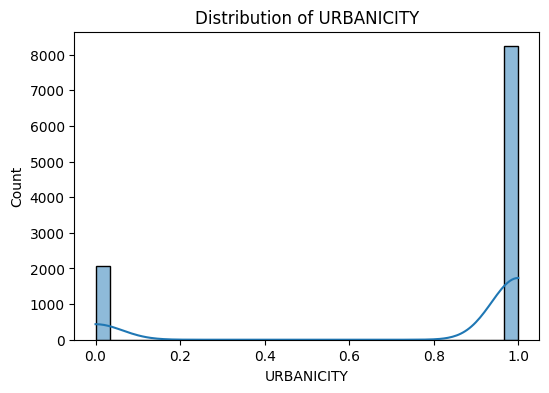

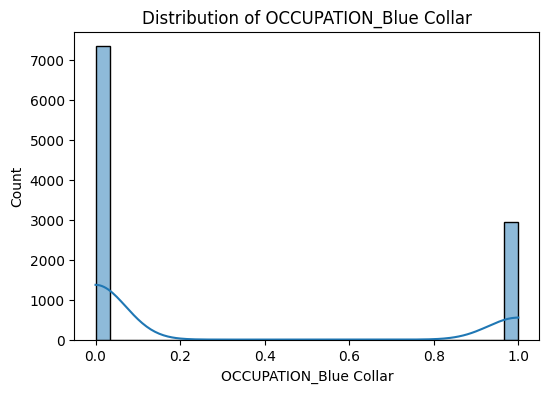

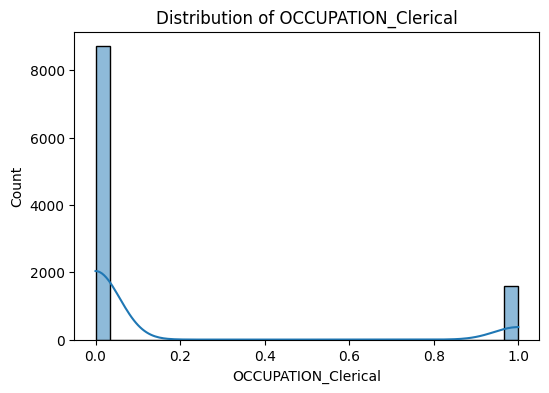

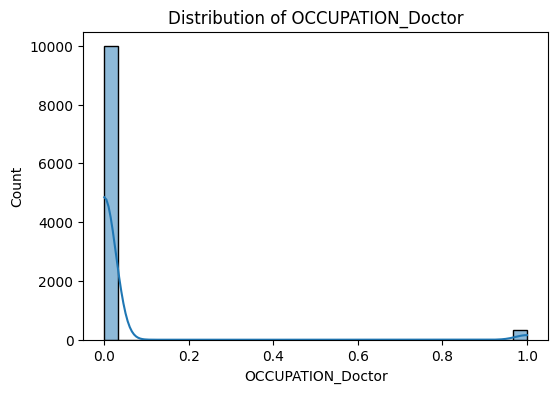

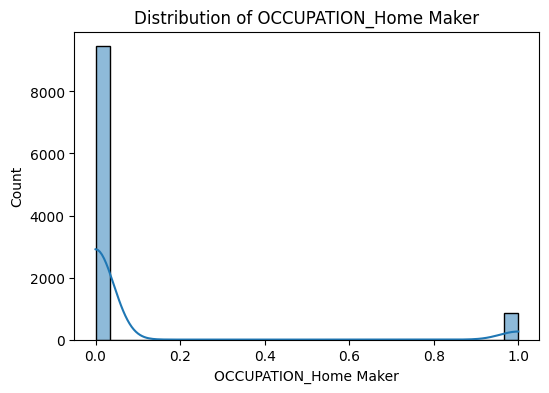

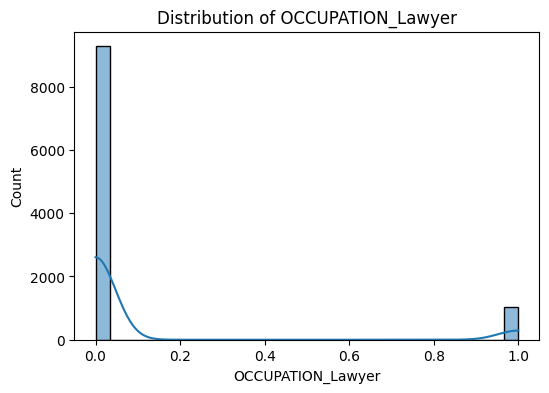

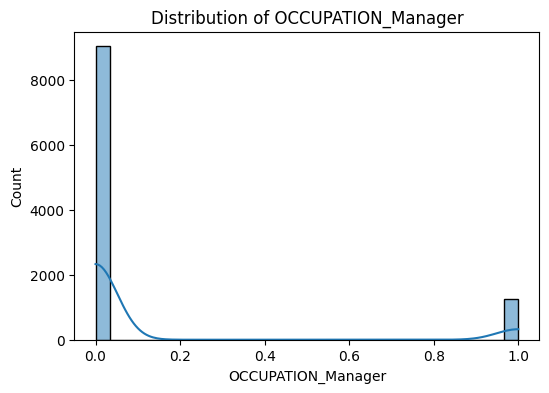

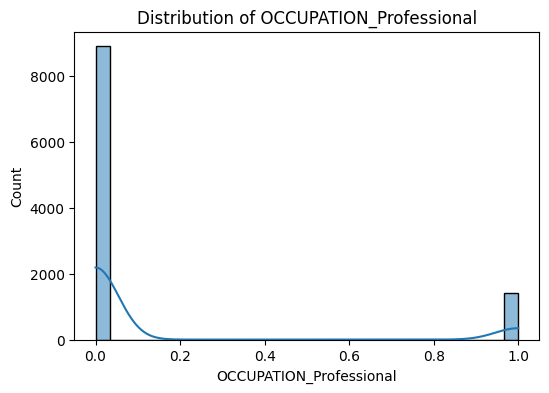

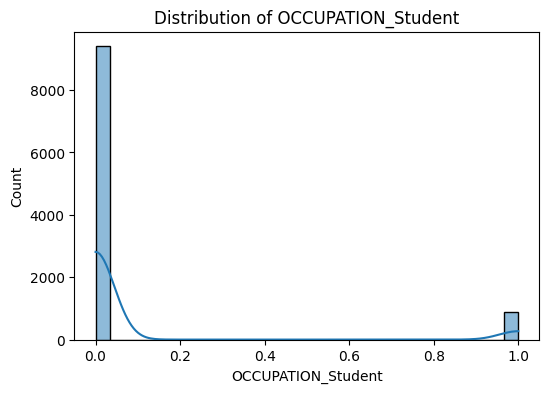

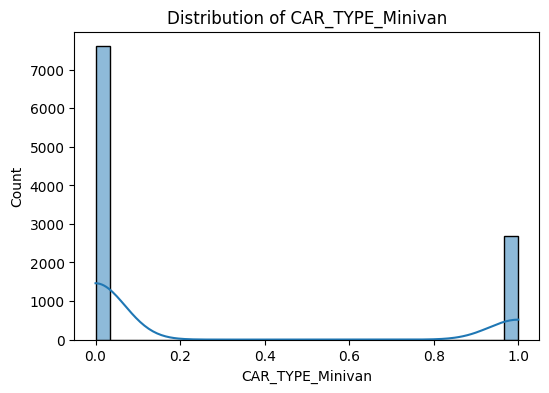

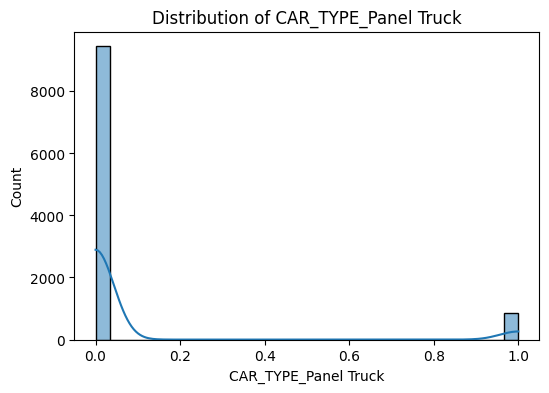

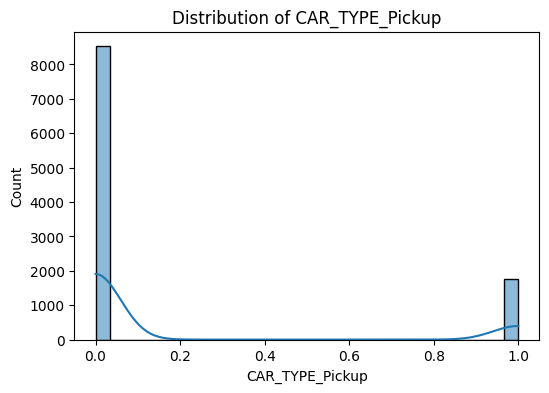

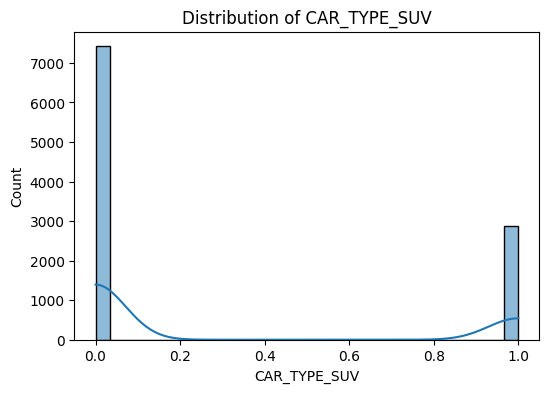

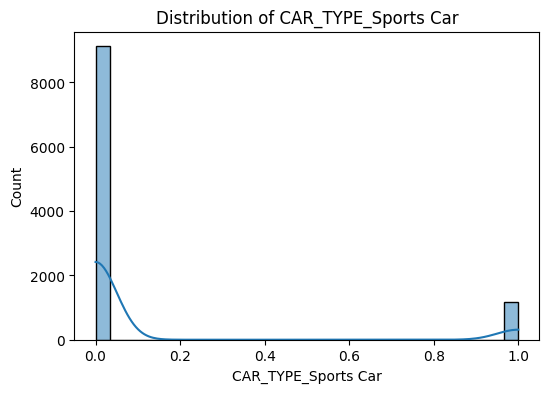

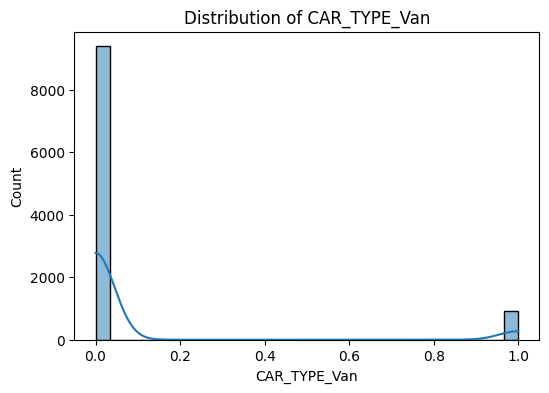

In [ ]:
#to display the distribution of each feature through historhrams
for col in df.columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

In [ ]:
#distribution of CLM_AMT
df["CLM_AMT"].describe()

,CLM_AMT
count,10301.000000
mean,0.015670
std,0.041013
min,0.000000
25%,0.000000
50%,0.000000
75%,0.013253
max,0.693147


In [ ]:
#Apply binning using quantiles into 5 groups
df2["CLM_AMT_BIN"] = pd.qcut(df["CLM_AMT"], q=5, labels=False, duplicates='drop')

In [ ]:
# Seperate features and target variable
X = df2.drop(['CLM_AMT', 'CLM_AMT_BIN'], axis=1)
y = df['CLM_AMT']

#create train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = df2['CLM_AMT_BIN'])


In [ ]:
#Linear Regression Modelling
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

#Linear Regression Metrics
mse_lin = mean_squared_error(y_test, y_pred_lin)
rmse_lin = np.sqrt(mse_lin)
r2_lin = r2_score(y_test, y_pred_lin)
print("Linear Regression Results:")
print("RMSE:", rmse_lin)
print("R^2:", r2_lin)

lin_reg_coef = pd.DataFrame(lin_reg.coef_, index=X.columns, columns=['Coefficient'])
lin_reg_coef

Linear Regression Results:
RMSE: 0.02617649400538281
R^2: 0.46591273100810715


,Coefficient
KIDSDRIV,0.002220
AGE,0.000340
HOMEKIDS,0.000559
YOJ,0.000017
INCOME,-0.000080
PARENT1,0.002056
HOME_VAL,0.000281
MSTATUS,-0.001073
EDUCATION,0.002329
TRAVTIME,0.000629


In [ ]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

param_grid = {
    'svr__C': [1, 10, 100],
    'svr__epsilon': [0.01, 0.05, 0.1, 0.5],
    'svr__kernel': ['poly'],
    'svr__gamma': ['scale', 'auto']
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV MSE (negative):", grid_search.best_score_)

NameError: name 'Pipeline' is not defined


Support Vector Regression Results on Test Set:
RMSE: 0.025159495974785548
R^2: 0.1885306934053238


In [ ]:
#SVR Modelling
svr = SVR(kernel='rbf', C=1, epsilon=0.01, gamma = 'auto')
svr.fit(X_train, y_train)
y_pred_svr = svr.predict(X_test)

# Evaluate SVR
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)
print("\nSupport Vector Regression Results:")
print("RMSE:", rmse_svr)
print("R^2:", r2_svr)


Support Vector Regression Results:
RMSE: 0.02207885763224571
R^2: 0.3750843189444607
